# 07 · 가격 반응·ETF 상대 움직임·CNN 후보 인계

**연구 질문 (H5).**
- 05·06 에서 찾은 변동성 국면 구간에서 가격은 어떤 방향과 크기로 움직였는가?
- 같은 날짜의 다른 ETF 와 비교하면 어떤 상대적 특성이 있었는가?
- 기존 CUSUM 경보와 가격 움직임은 시간적으로 어떤 관계였는가?
- 이 구간들을 CNN 특징학습 후보로 넘길 때 무엇을 넘기고 무엇을 넘기지 말아야 하는가?

**왜 필요한가.** 이 연구의 주 대상은 방향과 무관한 변동성 국면이다 (D1). 그러나 팀의 상위 주제는 'ETF 급등 국면 탐지' 다. 그래서 변동성 국면이 가격 상승·하락과 어떻게 함께 나타나는지를 **신호와 분리된 결과**로 기술해 둬야 한다. 그래야 다음 연구가 변동성 후보를 급등 정답으로 오인하지 않는다.

**시점 규칙 (결정 4, 계약 §3-4).**

| 열 | 정의 | 언제 알 수 있나 |
|---|---|---|
| `C` (h) | $\sum_{s=t-h+1}^{t} r_s$ 과거 h 일 누적 로그수익률 [%] | t 종가 |
| `Z_A` (h) | $C/\sqrt{\sum_{s=t-h+1}^{t}\hat v_s}$ — 당시 1-step 예측분산의 사후 합으로 나눈 설명 점수 | t 종가 (다기간 사전 예측 아님) |
| `U_C` (h) | C 의 확장형 mid-rank 과거 분위 | t 종가 |
| `fwd_R` (h) | $\sum_{s=t+1}^{t+h} r_s$ 미래 h 일 | **t+h 종가 이후 (사후)** |
| `fwd_Zfix_A` | $R/\sqrt{h\,\hat v_t}$ — t 시점 분산 수준을 고정한 대용치 | t+h 이후 |
| `fwd_Zpost_A` | $R/\sqrt{\sum_{s=t+1}^{t+h}\hat v_s}$ — 미래 1-step 예측의 사후 합 | t+h 이후 |

- Z 점수는 h-step 조건부분산 예측이 아니다. 보정된 Z-검정의 p값으로 쓰지 않는다.
- 주 정책은 A 이고, B·base 는 민감도다. 비양수 `vhat` 이 들어간 창은 계산하지 않는다 (05 §1: 정책 A 9일).

**상대수익률 4종 (계약 [A-11]·[A-12]).**
1. **단순 차이**: $C_i-\text{median}_{j\neq i}C_j$
2. **표준화 차이**: $Z_{A,i}-\text{median}_{j\neq i}Z_{A,j}$
3. **동일 노출 상대**: KOSPI200 그룹 안에서 $C_i-m_i\,C_{069500}$ ($m$ = 명목 배수 +1·+2·−1)
4. **노출 조정**: $C_i/m_i$ 를 다른 ETF 의 같은 값 중앙값과 비교. 다른 자산유형 중앙값 대비 차이도 함께 제시한다.

경제적 노출이 다른 ETF 사이의 단순 상승률 차이는 우열이나 위험조정 성과가 아니다.

## 0. 실행 환경·동결 입력 검증

In [1]:
# 새 커널 첫 셀: BLAS 스레드를 NumPy 로드 전에 1로 고정해 결과를 결정적으로 만든다.
import os  # 환경변수 설정
import sys  # 인터프리터·모듈 경로 확인
from pathlib import Path  # 저장소 상대 경로

for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):  # 네 BLAS 계열 변수
    os.environ[key] = "1"  # 다중 스레드 합산 순서에 따른 비트 차이를 막는다
assert "numpy" not in sys.modules, "새 커널에서 첫 셀부터 실행해야 합니다"  # 숨은 커널 상태 금지
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "configs/t14_multihorizon_w2_v1.json").is_file())  # 저장소 루트 탐색
sys.path.insert(0, str(ROOT / "src"))  # 이 작업트리의 r2h 패키지를 우선 사용

import csv  # 보호 파일 SHA 목록
import importlib.metadata as metadata  # 설치 패키지 버전 조회
import json  # 설정·인계 파일
import platform  # Python 버전

import matplotlib.pyplot as plt  # 그림 기본 설정
import numpy as np  # 수치 배열
import pandas as pd  # 결과표
from IPython.display import Image, display  # 표·그림 출력
from matplotlib import font_manager  # 한글 글꼴 등록

# T12·W1 재현 환경과 같은 버전이어야 한다 (user-site 의 다른 numpy/pandas 를 잡으면 여기서 멈춘다).
EXPECTED_ENV = {"python": "3.12.3", "numpy": "2.5.4", "pandas": "3.0.6", "scipy": "1.18.1", "matplotlib": "3.11.2"}  # W2 고정 환경
ACTUAL_ENV = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": metadata.version("scipy"), "matplotlib": metadata.version("matplotlib")}  # 실제 커널
assert ACTUAL_ENV == EXPECTED_ENV, f"실행 환경 불일치: {ACTUAL_ENV}"  # 버전 불일치는 재현 실패로 처리
assert "site-packages" in np.__file__ and ".local" not in np.__file__, np.__file__  # user-site 패키지 차단
FONT_FILE = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")  # 한글 도판용 나눔고딕
assert FONT_FILE.is_file(), "한글 도판 렌더링을 위한 나눔고딕 파일이 없습니다"  # 글꼴 없으면 중단
font_manager.fontManager.addfont(str(FONT_FILE))  # matplotlib 글꼴 목록에 등록
plt.rcParams["font.family"] = [font_manager.FontProperties(fname=str(FONT_FILE)).get_name(), "DejaVu Sans"]  # 한글 우선·기호 대체
plt.rcParams["axes.unicode_minus"] = False  # 음수 기호 깨짐 방지
pd.set_option("display.width", 200)  # 표 줄바꿈 완화
pd.set_option("display.max_columns", 40)  # 열 생략 완화

from r2h.multihorizon.core import load_cfg, sha256  # W2 동결 설정·해시
from r2h.window_study.empirical import verify_frozen  # T12 동결 입력 검증 (W1 함수 재사용)
from r2h.window_study.simulation import load_cfg as load_w1_cfg  # W1 동결 설정

CFG = load_cfg(ROOT)  # W2 동결 설정 configs/t14_multihorizon_w2_v1.json
CFG_W1 = load_w1_cfg(ROOT)  # W1 동결 설정 configs/t13_window_study_v1.json (읽기만)
SOURCE = Path(os.environ.get("T12_FROZEN_ROOT", ROOT.parents[1] / "1016/R2H_T12_Final")).resolve()  # T12 종결 작업트리 (명시 경로)
assert SOURCE.name == "R2H_T12_Final" and SOURCE.is_dir(), SOURCE  # 새 위치의 형제 기본값이 아닌 실제 경로
assert Path(sys.modules["r2h"].__file__).resolve().is_relative_to((ROOT / "src").resolve())  # 다른 트리의 r2h 금지
FROZEN = verify_frozen(ROOT, SOURCE, CFG_W1)  # 00·01·02 노트북·원자료 22개·run manifest·일별 cache 20종 대조
# 계약·설정 동결 SHA 와 W1 보호 파일 153개를 대조한다.
FREEZE = [line.split(maxsplit=1) for line in (ROOT / "research/multihorizon_w2/CONTRACT_FREEZE_SHA256.txt").read_text().splitlines()[:3]]  # 동결 기록
for digest, name in FREEZE:  # 설정·계약·보호목록
    assert sha256(ROOT / name) == digest, f"동결 파일 변경: {name}"  # 결과를 본 뒤 규칙 변경 금지
PROTECTED = list(csv.DictReader(open(ROOT / "research/multihorizon_w2/W1_PROTECTED_SHA256.csv", encoding="utf-8")))  # 7205e91 시점 해시
CHANGED = [r["path"] for r in PROTECTED if sha256(ROOT / r["path"]) != r["sha256_at_7205e91"]]  # 바뀐 W1 파일
assert not CHANGED, f"W1 보호 파일 변경: {CHANGED}"  # W1 결과·노트북·계약은 읽기만
BASE = ROOT / "research/multihorizon_w2"  # W2 산출물 폴더
FIG = BASE / "figures"  # 그림 폴더
FIG.mkdir(parents=True, exist_ok=True)  # 없으면 만든다
print("작업트리:", ROOT)  # 실행 위치 기록
print("동결 T12:", FROZEN)  # 입력 검증 결과
print("W2 프로토콜:", CFG["protocol_version"], "| 설정 SHA256:", FREEZE[0][0][:16], "| 계약 SHA256:", FREEZE[1][0][:16])  # 동결 지문
print("W1 보호 파일", len(PROTECTED), "개 불변 · 실행 환경:", ACTUAL_ENV)  # 보호·환경 기록

작업트리: /home/sieg/projects-wsl/hongik_univ_26_2/SA/1017/R2H_MultiHorizon_Volatility_Regime
동결 T12: {'run_id': 'b_nb_20261016T181251', 'data_version': '5f20e3e0073b521a', 'notebook_count': 3, 'raw_sha_count': 22, 'daily_ticker_count': 20, 'source_root': '/home/sieg/projects-wsl/hongik_univ_26_2/SA/1016/R2H_T12_Final'}
W2 프로토콜: W2-lock-1 | 설정 SHA256: 9fa948762e9f7bfb | 계약 SHA256: 4dec1d40adc3d01a
W1 보호 파일 153 개 불변 · 실행 환경: {'python': '3.12.3', 'numpy': '2.5.4', 'pandas': '3.0.6', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 1. 05·06 결과 및 후보 구간 해시 검증

In [2]:
# 06→07 인계 검증 (05·06 결과 CSV 와 05 일별 파일 해시) 후 07 계산.
# 07 단계 계산 함수 (src/r2h/multihorizon/stage07.py)
from r2h.multihorizon.stage07 import regime_relative_table, run_stage07, same_exposure_tracking

SOURCE_COMMITS = "base=7205e91348c38584ecca74ea64e4bbc426730e86;contract=1fbdb1d;w2_release=see research/multihorizon_w2/W2_RELEASE_MANIFEST.json"  # 출처 커밋 (릴리스 커밋은 매니페스트에 기록)
S07 = run_stage07(ROOT, SOURCE, CFG, SOURCE_COMMITS)  # 인계 해시 불일치면 여기서 멈춘다
H06 = S07["handoff06"]  # 06 인계 내용
assert H06["config_sha256"] == FREEZE[0][0] and H06["contract_sha256"] == FREEZE[1][0] and H06["environment"] == ACTUAL_ENV  # 같은 계약·환경
assert sha256(BASE / "results/06/figure_index_06.csv") == H06["figure_index_sha256"]  # 06 그림 색인 불변
print("06 인계 검증 통과: 05·06 결과", len(H06["results"]), "개 · 05 일별 파일", len(H06["work_files"]), "개 SHA256 일치")  # 결과

06 인계 검증 통과: 05·06 결과 22 개 · 05 일별 파일 3 개 SHA256 일치


## 2. 과거·미래 가격 반응의 구분 검사

과거 h 일 값이 t 이후 수익률을 쓰지 않는지, 미래 h 일 값이 t 이전 수익률을 쓰지 않는지를 실제 자료로 확인한다.

In [3]:
# 시점 검사: 원자료에서 직접 계산한 과거·미래 합과 엔진 값을 비교하고, 미래값을 오염시켜 과거 열이 그대로인지 본다.
from r2h.multihorizon.stage07 import forward_sum, trailing_sum  # 합 함수

PF = S07["price"]  # 20종 × 날짜 × h 가격 특징 (Git 제외 파일과 동일)
RW = S07["r_wide"]  # 날짜 × 20종 % 로그수익률
r0 = RW["069500"].to_numpy()  # 069500 수익률
t = RW.index.get_loc(pd.Timestamp("2024-08-05"))  # 예시 날짜 위치
row = PF[(PF.ticker == "069500") & (PF.h == 20) & (PF.date == pd.Timestamp("2024-08-05"))].iloc[0]  # 엔진 행
assert abs(row.C - r0[t - 19 : t + 1].sum()) < 1e-9 and abs(row.fwd_R - r0[t + 1 : t + 21].sum()) < 1e-9  # 정의대로
r_mut = r0.copy()  # 복사본
r_mut[t + 1 :] = 999.0  # t 이후를 오염
assert np.array_equal(trailing_sum(r_mut, 20)[: t + 1], trailing_sum(r0, 20)[: t + 1], equal_nan=True)  # 과거 합은 미래를 쓰지 않는다
r_mut2 = r0.copy()  # 복사본
r_mut2[: t + 1] = -999.0  # t 까지를 오염
assert np.isclose(forward_sum(r_mut2, 20)[t], forward_sum(r0, 20)[t])  # 미래 합은 t 까지를 쓰지 않는다
print(f"2024-08-05 069500: 과거 20일 C={row.C:.2f}% (t 종가에 앎) · 미래 20일 R={row.fwd_R:.2f}% (가용일 {row.fwd_available_at}) · Z_A={row.Z_A:.2f} · fwd_Zfix_A={row.fwd_Zfix_A:.2f}")  # 예시

2024-08-05 069500: 과거 20일 C=-17.08% (t 종가에 앎) · 미래 20일 R=7.80% (가용일 2024-09-03) · Z_A=-3.62 · fwd_Zfix_A=0.78


## 3. 기간별 누적수익률과 예측분산 대비 점수 — 전체 분포

In [4]:
# 2021–2025 전 ETF·전 거래일의 h 별 C·Z_A·fwd_R 분포 (비교 기준선).
CORE = PF[PF.date.dt.year.isin(CFG["core_years"])]  # 주 해석 연도
base_tab = CORE.groupby("h").agg(C_중앙=("C", "median"), C_양수비율=("C", lambda s: float((s > 0).mean())), Z_A_중앙절대=("Z_A", lambda s: float(s.abs().median())), Z_B_중앙절대=("Z_B", lambda s: float(s.abs().median())), Z_base_중앙절대=("Z_base", lambda s: float(s.abs().median())), fwd_R_중앙=("fwd_R", "median"), n=("C", "size")).round(3)  # h 별 요약
display(base_tab)  # 기준선
UNCOND = CORE.groupby("h").fwd_R.median().to_dict()  # 무조건부 미래 h 일 중앙값
print("Z_A 계산 불가 (비양수·결측 vhat 포함 창) 비율, h=20:", round(float(CORE[CORE.h == 20].Z_A.isna().mean()), 4))  # 결측 비율

,C_중앙,C_양수비율,Z_A_중앙절대,Z_B_중앙절대,Z_base_중앙절대,fwd_R_중앙,n
h,,,,,,,
1,0.014,0.521,0.654,0.522,0.617,0.014,24500
3,0.055,0.552,0.698,0.563,0.646,0.055,24500
7,0.122,0.558,0.706,0.576,0.656,0.120,24500
14,0.279,0.572,0.715,0.592,0.676,0.274,24500
20,0.387,0.578,0.704,0.586,0.680,0.377,24500
30,0.562,0.584,0.710,0.591,0.695,0.561,24500
60,1.371,0.610,0.721,0.597,0.710,1.380,24500
120,2.732,0.623,0.817,0.670,0.808,3.011,24500


Z_A 계산 불가 (비양수·결측 vhat 포함 창) 비율, h=20: 0.0042


**해석.**
- 2021–2025 의 20일 누적 로그수익률은 ETF·날짜를 합쳐 보면 중앙값이 약 +0.38% 다.
- |Z_A| 중앙값이 h 와 함께 크게 변하지 않는다. 1-step 예측분산의 합이 h 일 수익률 변동을 대체로 같은 척도로 정규화한다는 뜻이다.
- 표준정규라면 |Z| 중앙값은 0.67 이다. 관측값 0.65–0.82 는 그 근처다 (h=120 에서 가장 크다).
- 이 표는 아래 국면별 반응의 비교 기준이다. 국면별 값은 이 기준과 함께 읽는다.

## 4. 변동성 확대·축소·고·저 국면별 가격 방향과 분포

,pre_C_h20,during_C,post_R_h20,post_Zfix_A_h20,post_Zpost_A_h20,during_rel_simple,post_rel_h20,during_양수비율,post20_양수비율,n
channel,,,,,,,,,,
CONTRACTION,1.402,0.019,0.575,0.253,0.205,0.044,-0.665,0.531,0.615,262
EXPANSION,0.107,0.069,0.249,0.262,0.308,0.113,-0.536,0.565,0.597,253
HIGH_LEVEL,0.156,0.509,0.690,0.251,0.314,0.248,-0.184,0.603,0.624,290
LOW_LEVEL,1.110,0.009,-0.186,-0.049,-0.044,-0.010,-0.636,0.512,0.482,363


channel,CONTRACTION,EXPANSION,HIGH_LEVEL,LOW_LEVEL
year_status,,,,
PARTIAL_NON_BLIND,30,0,14,3
PILOT,0,0,0,0
PRIMARY,0,0,0,0


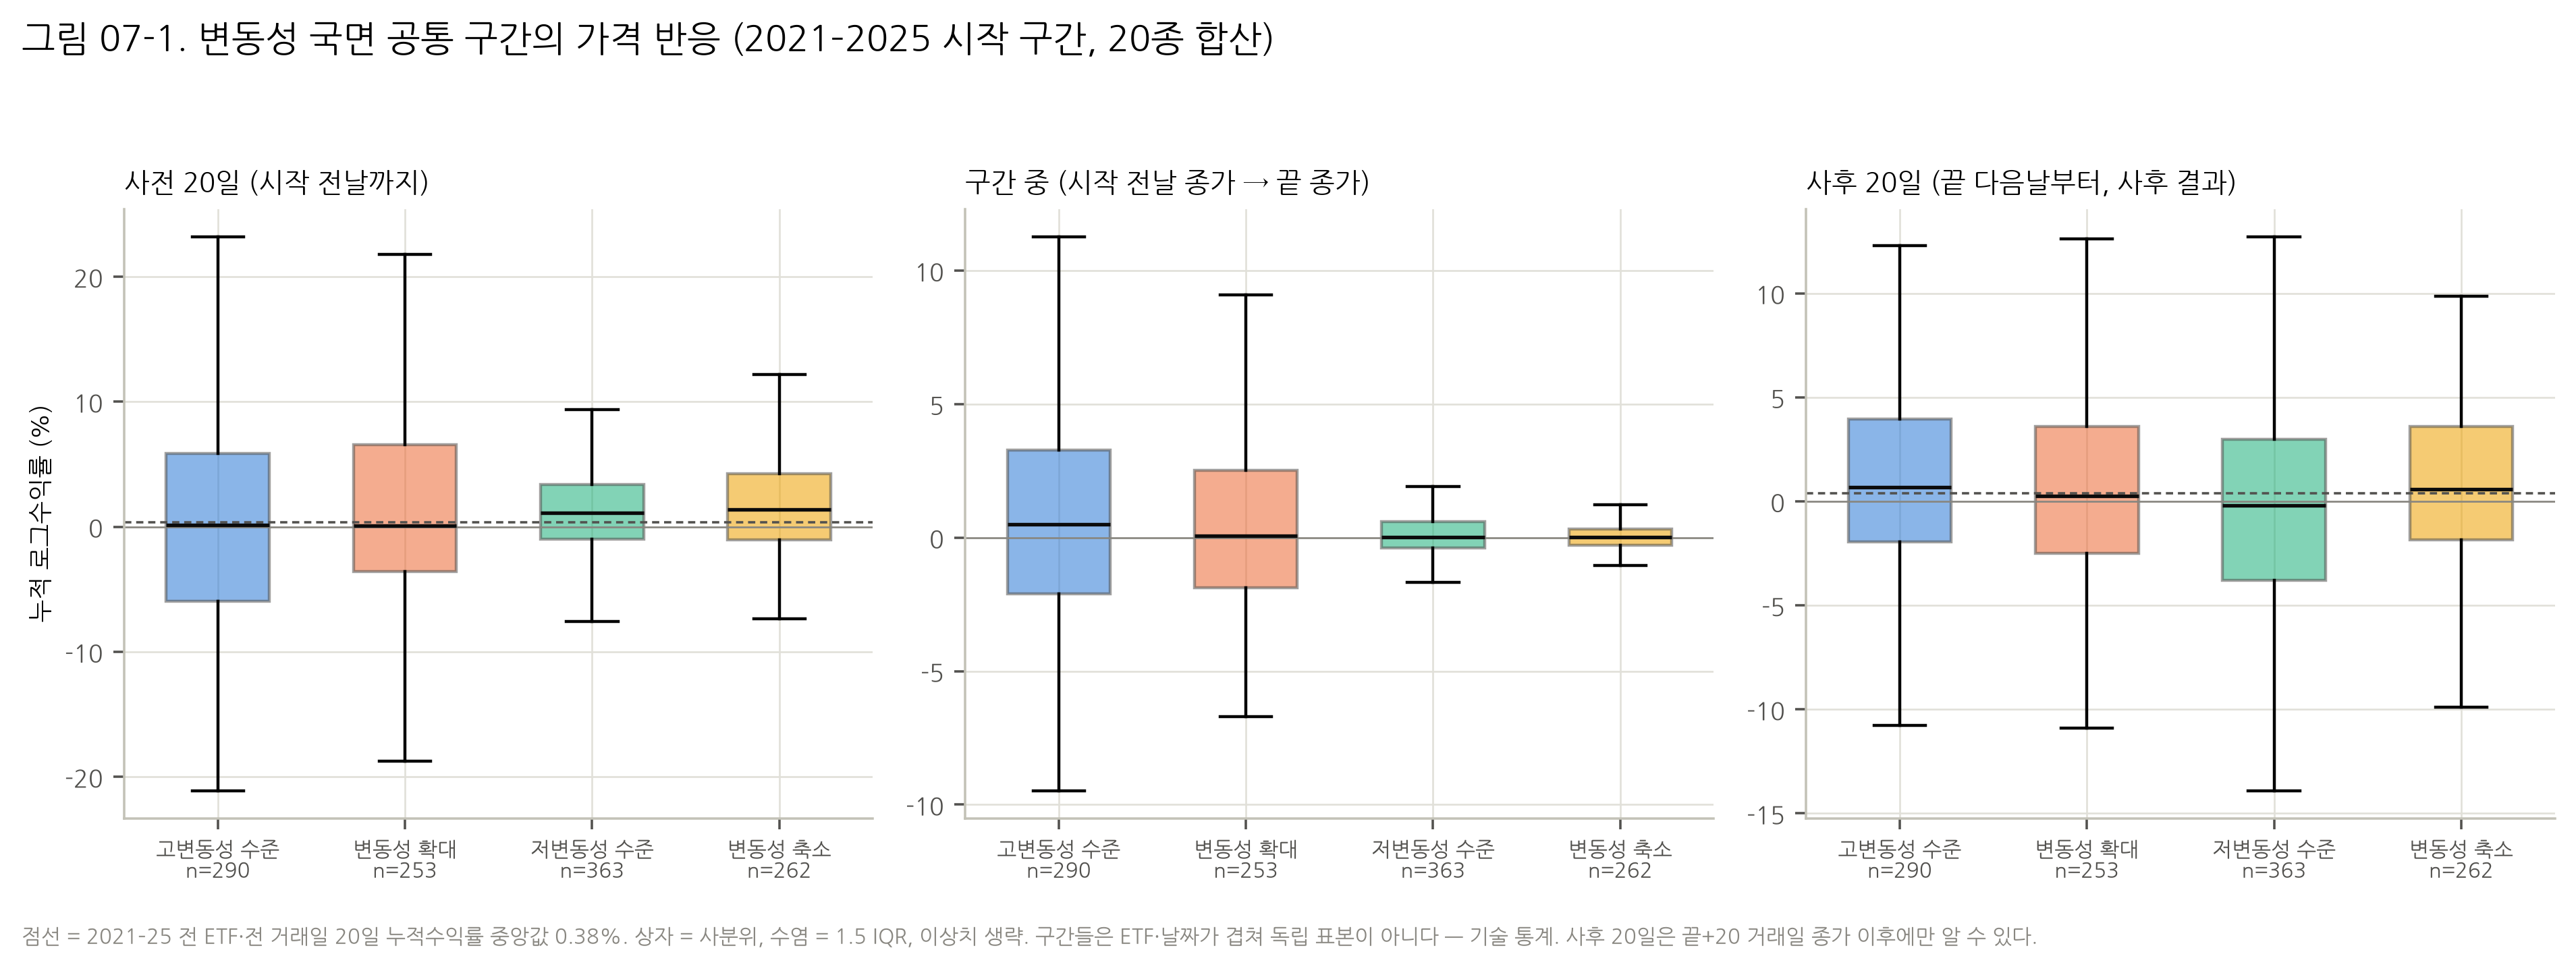

In [5]:
# 2021–2025 시작 공통 구간의 사전·구간 중·사후 반응 요약과 그림 07-1.
from r2h.multihorizon import figures as F  # W2 그림 함수

RE = S07["reaction"]  # 구간별 가격 반응
P_RE = RE[RE.year_status == "PRIMARY"]  # 주 해석 구간
cols = ["pre_C_h20", "during_C", "post_R_h20", "post_Zfix_A_h20", "post_Zpost_A_h20", "during_rel_simple", "post_rel_h20"]  # 열
summ = P_RE.groupby("channel")[cols].median().round(3)  # 중앙값
summ["during_양수비율"] = P_RE.groupby("channel").during_C.apply(lambda s: float((s > 0).mean())).round(3)  # 구간 중 상승 비율
summ["post20_양수비율"] = P_RE.groupby("channel").post_R_h20.apply(lambda s: float((s > 0).mean())).round(3)  # 사후 상승 비율
summ["n"] = P_RE.groupby("channel").size()  # 구간 수
display(summ)  # 채널별 반응
NA_END = RE.groupby(["year_status", "channel"]).post_available_at_h20.apply(lambda s: int((s == "NOT_AVAILABLE_DATA_END").sum())).unstack(fill_value=0)  # 자료 끝 결측
display(NA_END)  # 사후 20일을 계산할 수 없는 구간 수 (2026 에 집중)
FIG_FILES = []  # 그림 목록
FIG_FILES += F.reaction_boxes(RE, UNCOND, FIG, "07-1")  # 그림 07-1
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시

**해석 (그림 07-1, 2021–2025 시작 구간).**
- **방향은 섞여 있다.** 구간 중 상승 비율은 고변동성 60.3%, 확대 56.5%, 저변동성 51.2%, 축소 53.1% 다. 변동성 확대·고변동성은 하락만이 아니라 상승 급변도 포함한다.
- **구간 중 수익률 중앙값은 고변동성 +0.51% 로 가장 크고, 나머지는 0 근처다.** 고변동성 구간은 길어서(중앙값 3일, 최대 127일) 상승 추세가 겹쳐 든다.
- **사전 20일:** 저변동성(+1.11%)과 축소(+1.40%)는 조용한 상승 뒤에 나타난다. 확대(+0.11%)와 고변동성(+0.16%)은 기준선(+0.38%)보다 약한 가격 뒤에 나타난다.
- **사후 20일 (사후 결과):** 고변동성 +0.69%, 축소 +0.57%, 확대 +0.25%, 저변동성 −0.19% 다. 기준선 +0.38% 와의 차이는 날짜·ETF 가 겹친 구간들의 기술 통계다. 예측력 주장이 아니다.
- **자료 끝 결측.** 2026 구간은 사후 20일을 계산할 수 없는 경우가 많다 (축소 30/73, 고변동성 14/59). 결측을 버리지 않고 `NOT_AVAILABLE_DATA_END` 로 센다. 2021–2025 구간은 모두 계산 가능하다.

## 5. ETF 별 과거 기준 대비 가격 반응과 전후 궤적

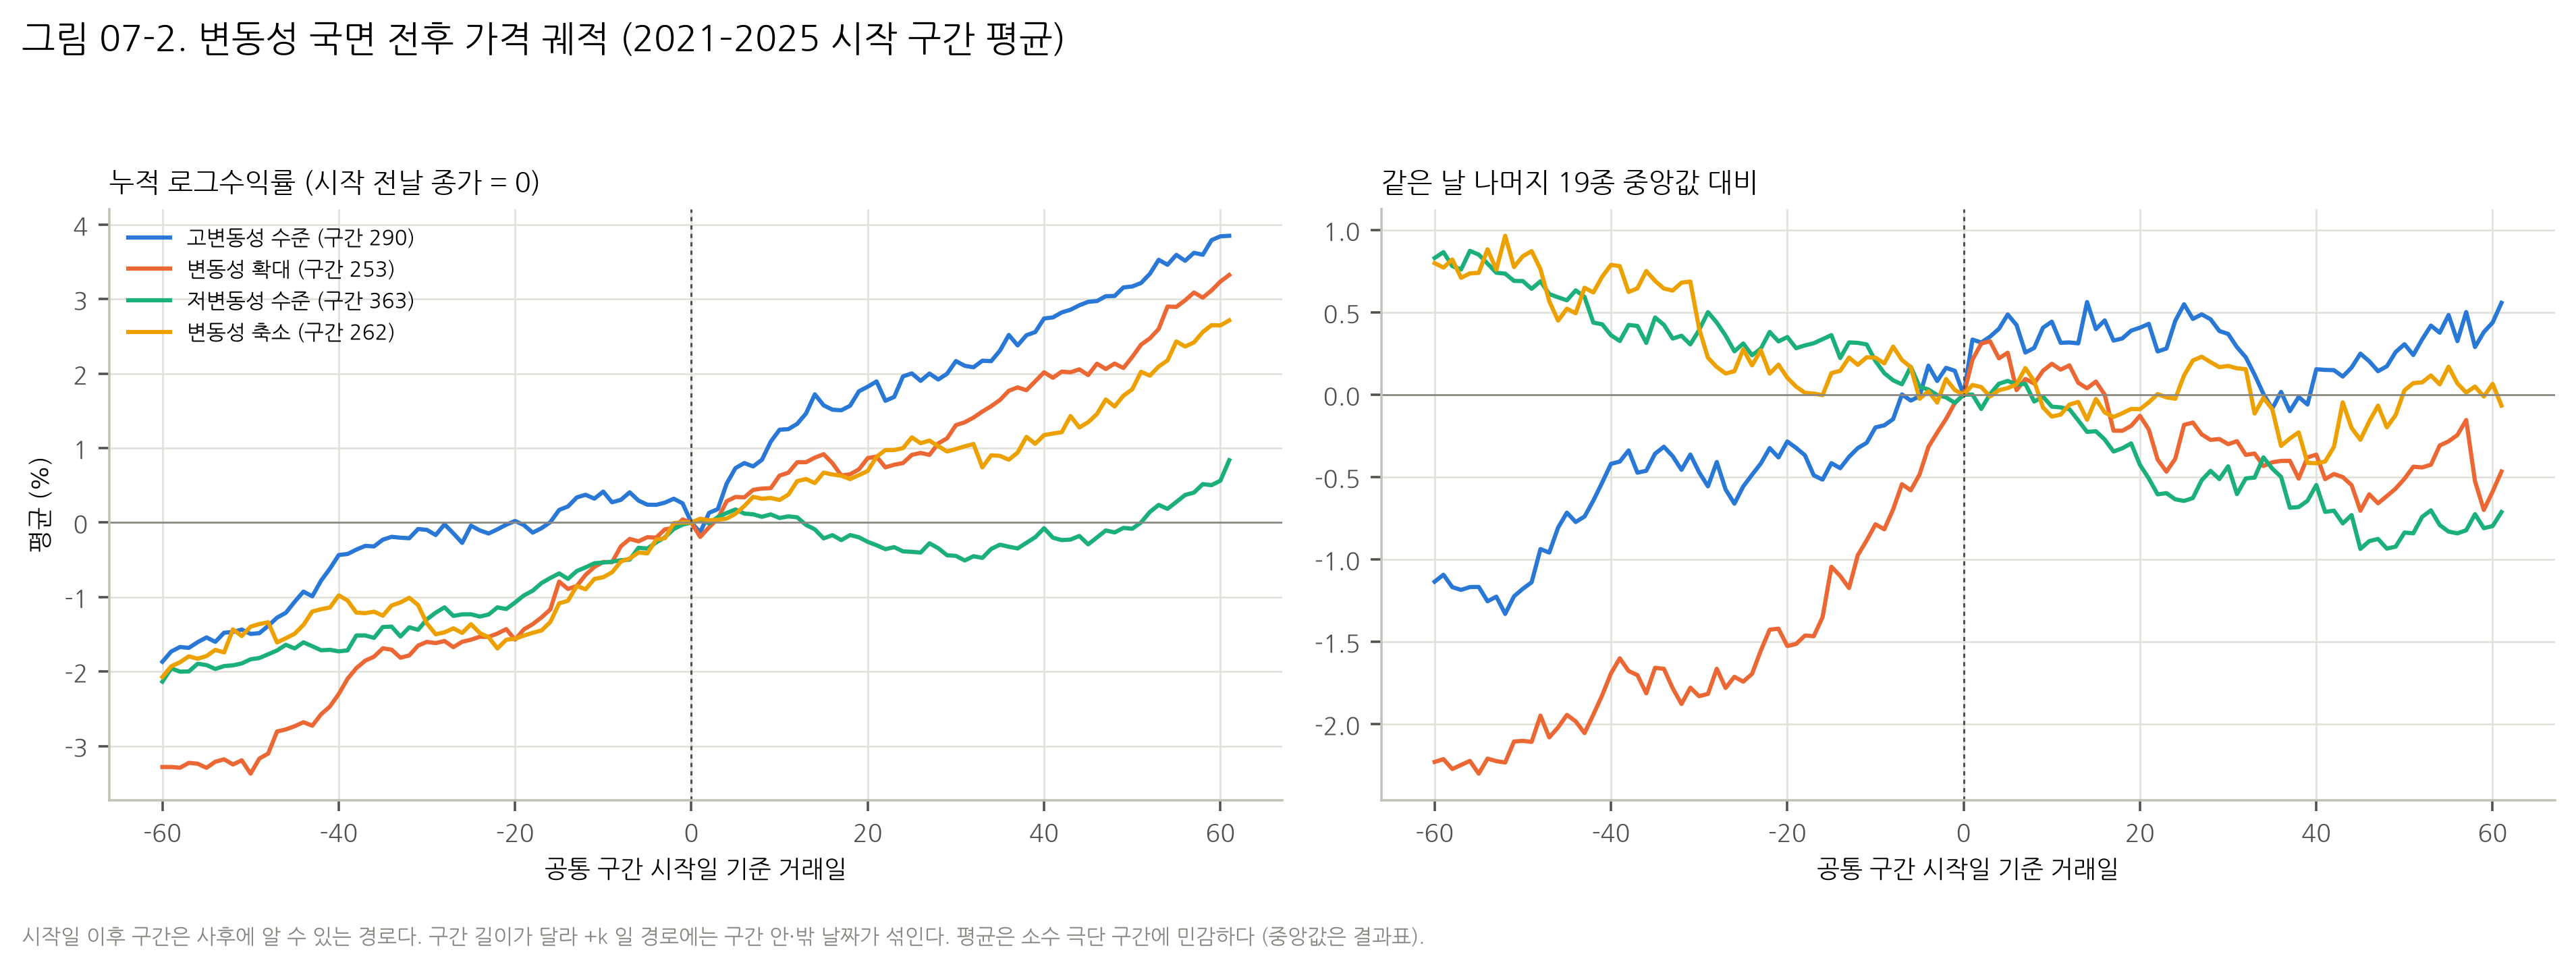

,channel,overlap_candidate_day,median_C,median_Z_A,median_U_C,median_rel_simple,median_rel_std,median_rel_exposure_adj,median_rel_cross_asset,median_fwd_R,share_C_pos,n_etf_days
0,CONTRACTION,False,0.372,0.192,0.497,0.002,0.001,0.004,0.044,0.362,0.577,24019
1,CONTRACTION,True,1.321,0.351,0.541,-0.168,-0.048,-0.255,0.023,0.889,0.651,481
2,EXPANSION,False,0.431,0.199,0.500,-0.009,-0.004,-0.003,0.043,0.378,0.582,23403
3,EXPANSION,True,0.055,0.059,0.416,0.281,0.112,0.093,0.062,0.358,0.511,1097
4,HIGH_LEVEL,False,0.520,0.197,0.497,-0.006,-0.007,-0.011,0.044,0.395,0.583,21962
5,HIGH_LEVEL,True,0.135,0.175,0.521,0.055,0.094,0.210,0.035,0.321,0.540,2538
6,LOW_LEVEL,False,0.333,0.185,0.497,0.002,0.003,0.006,0.028,0.421,0.573,22741
7,LOW_LEVEL,True,1.047,0.278,0.505,-0.008,-0.026,-0.043,0.229,-0.064,0.650,1759


In [6]:
# 구간 시작 ±60 거래일 평균 경로 (절대·상대) 와, 후보일의 과거 20일 수익률 과거 분위 U_C.
PM = pd.read_csv(BASE / "results/07/interval_path_mean.csv", header=[0, 1], index_col=[0, 1])  # 저장된 평균 경로 (2021–25)
FIG_FILES += F.path_figure(PM, FIG, "07-2")  # 그림 07-2
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시
OV = pd.read_csv(ROOT / "outputs/t14/05/daily_overlap.csv.gz", dtype={"ticker": str}, parse_dates=["date"])  # 05 일별 중첩
REL = S07["relative"]  # 일별 상대 움직임
RT = regime_relative_table(OV, REL, PF, CFG)  # 채널 × 후보일 여부 요약 (h=20)
display(RT.round(3))  # 후보일 대 비후보일

**해석 (그림 07-2).** 경로는 시작 전날 종가를 0 으로 둔 누적 로그수익률이다. 그래서 −60 일의 값은 '시작 전 60일 수익률 × (−1)' 이다.
- **평균 기준.** 네 채널 모두 시작 전 60일 동안 올랐다. 확대 +3.28%, 저변동성 +2.14%, 축소 +2.07%, 고변동성 +1.87% 다.
  - 확대 구간 ETF 는 같은 기간 나머지 19종 중앙값보다 평균 2.23%p 더 올랐다.
  - 시작 뒤 60일 평균은 고변동성 +3.84%, 확대 +3.24%, 축소 +2.65%, 저변동성 +0.56% 다.
- **중앙값 기준 (결과표).** 크기가 훨씬 작다. 예를 들어 확대 구간의 시작 전 60일 상승은 +0.45%, 시작 뒤 60일은 +1.54% 다. 평균 경로는 2025 말–2026 국내 주식형처럼 큰 상승 구간 몇 개가 끌어올린 것이다.
- 따라서 '확대 직전에 가격이 올랐다' 를 일반 경향으로 읽지 않는다. 중앙값은 §4 의 사전 20일 표(+0.11%)와 같은 방향의 작은 값이다.
- ETF 자기 과거 기준(U_C)으로 보면 확대 후보일의 과거 20일 수익률 분위 중앙값은 0.42 로, 비후보일 0.50 보다 낮다. 확대는 그 ETF 기준으로 상대적으로 약한 가격 뒤에 나타나는 경향이 있다.
- 저변동성·축소 후보일은 과거 20일 상승 비율이 65% 로, 비후보일 57–58% 보다 높다.

## 6. 같은 날짜 다른 ETF 대비 상대수익률 · 서로 다른 자산군과의 상대 움직임

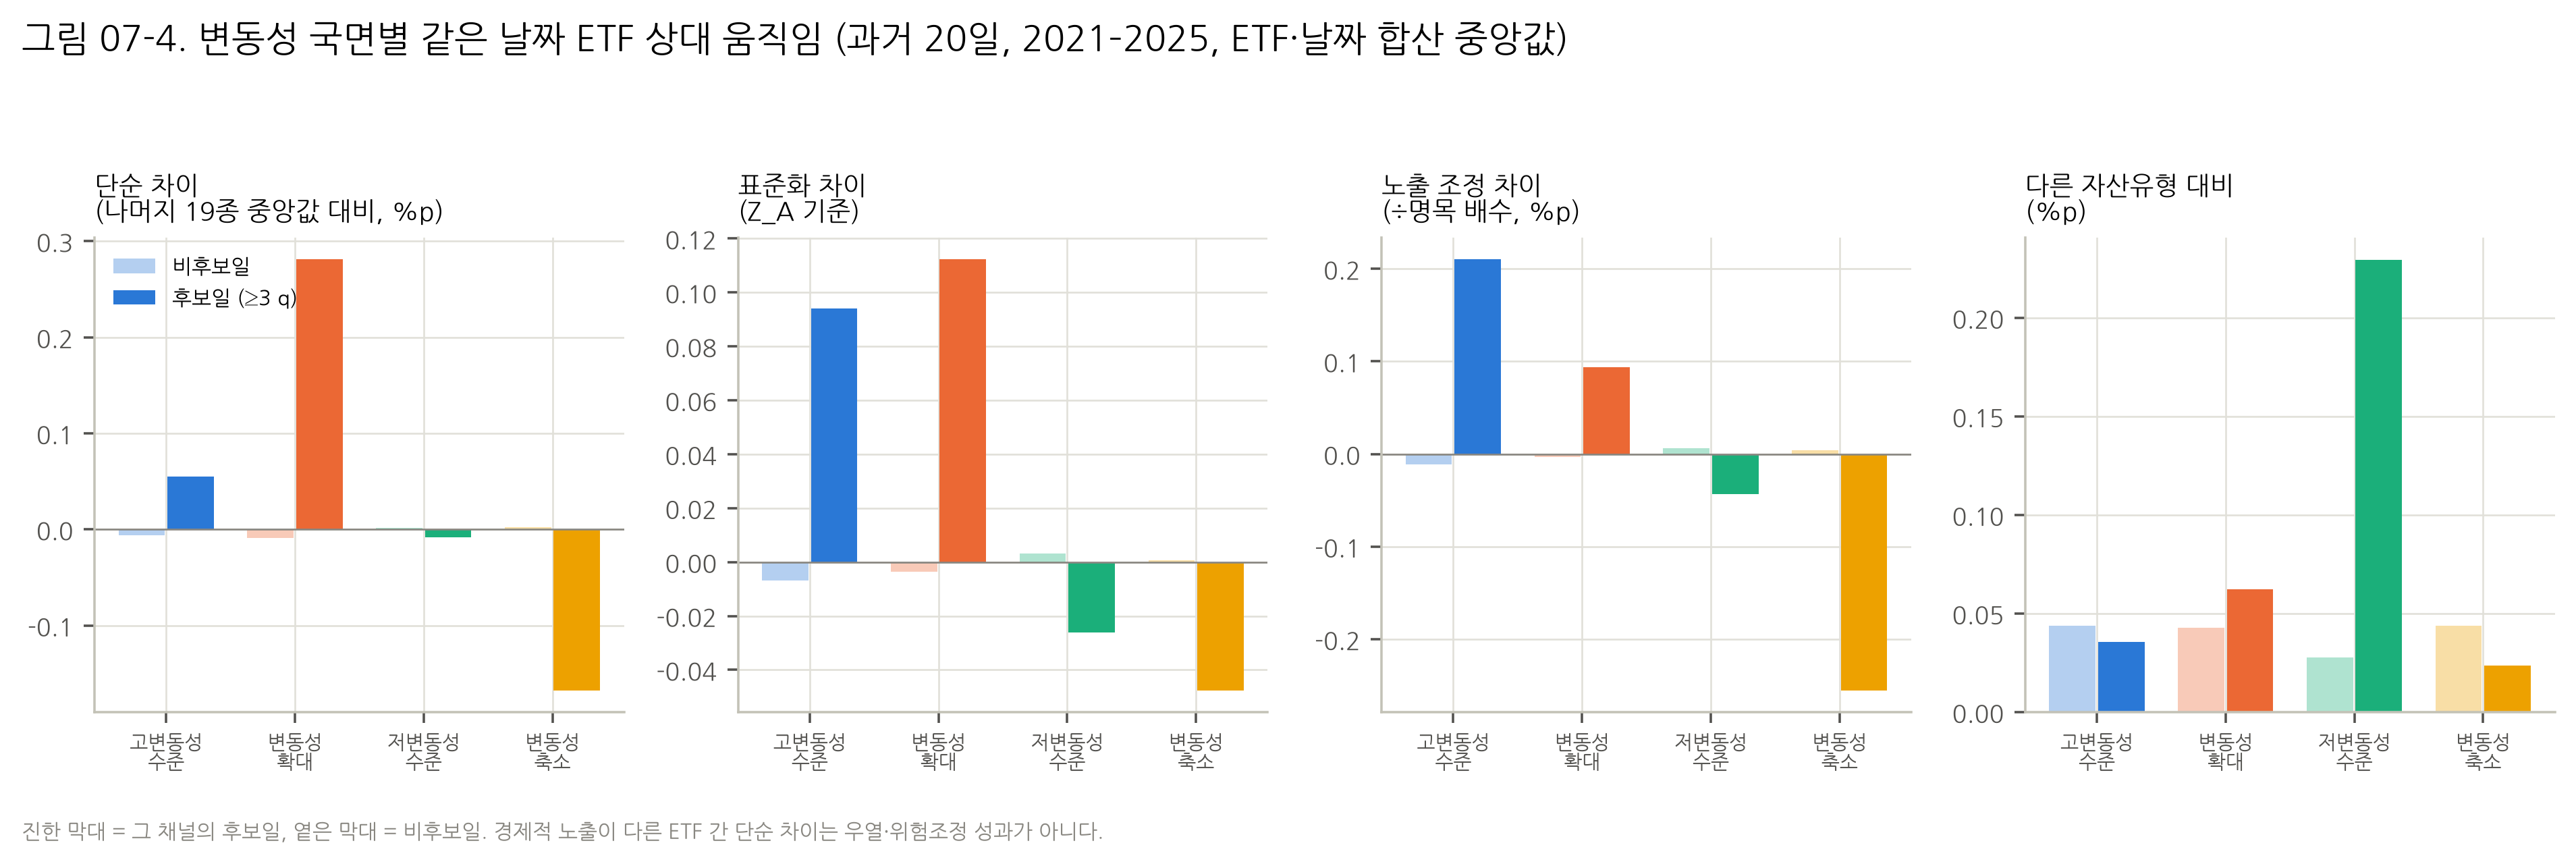

overlap_candidate_day,False,True
category,,
broad_market,0.261,-2.166
commodity,0.143,0.890
currency,0.116,0.271
leveraged_inverse,-0.573,-0.780
money_market,-0.351,-0.508
rates,-0.594,-0.435
sector,0.093,4.460
strategy,0.689,6.883
theme,-0.985,-0.538


In [7]:
# 그림 07-4: 채널별 후보일 대 비후보일의 상대 움직임 4종.
FIG_FILES += F.regime_relative_figure(RT, FIG, "07-4")  # 그림 07-4
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시
cat_rel = REL[(REL.h == 20) & REL.date.dt.year.isin(CFG["core_years"])].merge(OV[OV.channel == "EXPANSION"][["ticker", "date", "overlap_candidate_day"]], on=["ticker", "date"]).merge(S07["expo"][["ticker", "category"]], on="ticker")  # 확대 채널 × 자산유형
display(cat_rel.groupby(["category", "overlap_candidate_day"]).rel_cross_asset.median().unstack().round(3))  # 자산유형별 다른 유형 대비 (확대 후보일 여부)

**해석 (그림 07-4).**
- 확대 후보일의 과거 20일 단순 상대수익률 중앙값은 +0.28%p 다. 비후보일은 −0.01 이다.
  - 그 ETF 의 절대 수익률은 약했다 (C 중앙값 0.06%).
  - 그러나 같은 날 나머지 19종의 중앙값은 더 약했다.
  - 확대 후보일은 시장 전체가 흔들린 날에 몰려 있다 (06 의 2024-08·2025-04). 그래서 '그날 다른 ETF 보다 덜 빠졌다' 는 상대 효과가 함께 잡힌다.
- 고변동성 후보일의 노출 조정 상대값은 +0.21%p 다. 레버리지·인버스를 명목 배수로 나눈 뒤 비교한 값이다.
- 축소 후보일은 반대로 단순 상대 −0.17%p, 노출 조정 −0.26%p 다. 축소는 그 ETF 가 다른 ETF 보다 덜 오른 조용한 시기에 나타난다.
- 저변동성 후보일의 '다른 자산유형 대비' 값은 +0.23%p 다. 조용한 상승 국면에 있는 주식형이 채권·통화 대비 앞서는 구성이다.
- 모든 값은 ETF·날짜를 합친 중앙값이다. 경제적 노출이 다른 상품 사이의 성과 우열로 읽지 않는다.

## 7. 동일 지수 ETF 의 추적 차이 — 레버리지·인버스 구조

,ticker,overlap_candidate_day,n,median,q10,q90,mean_abs
0,069500,False,1118,0.009,-0.074,0.097,0.055
1,069500,True,107,0.016,-0.067,0.093,0.053
2,102110,False,1118,0.009,-0.074,0.097,0.055
3,102110,True,107,0.016,-0.067,0.093,0.053
4,114800,False,1118,0.033,-0.380,0.397,0.251
5,114800,True,107,-0.535,-0.922,-0.090,0.515
6,122630,False,1118,-0.544,-0.926,-0.181,0.558
7,122630,True,107,-1.211,-1.747,-0.608,1.179


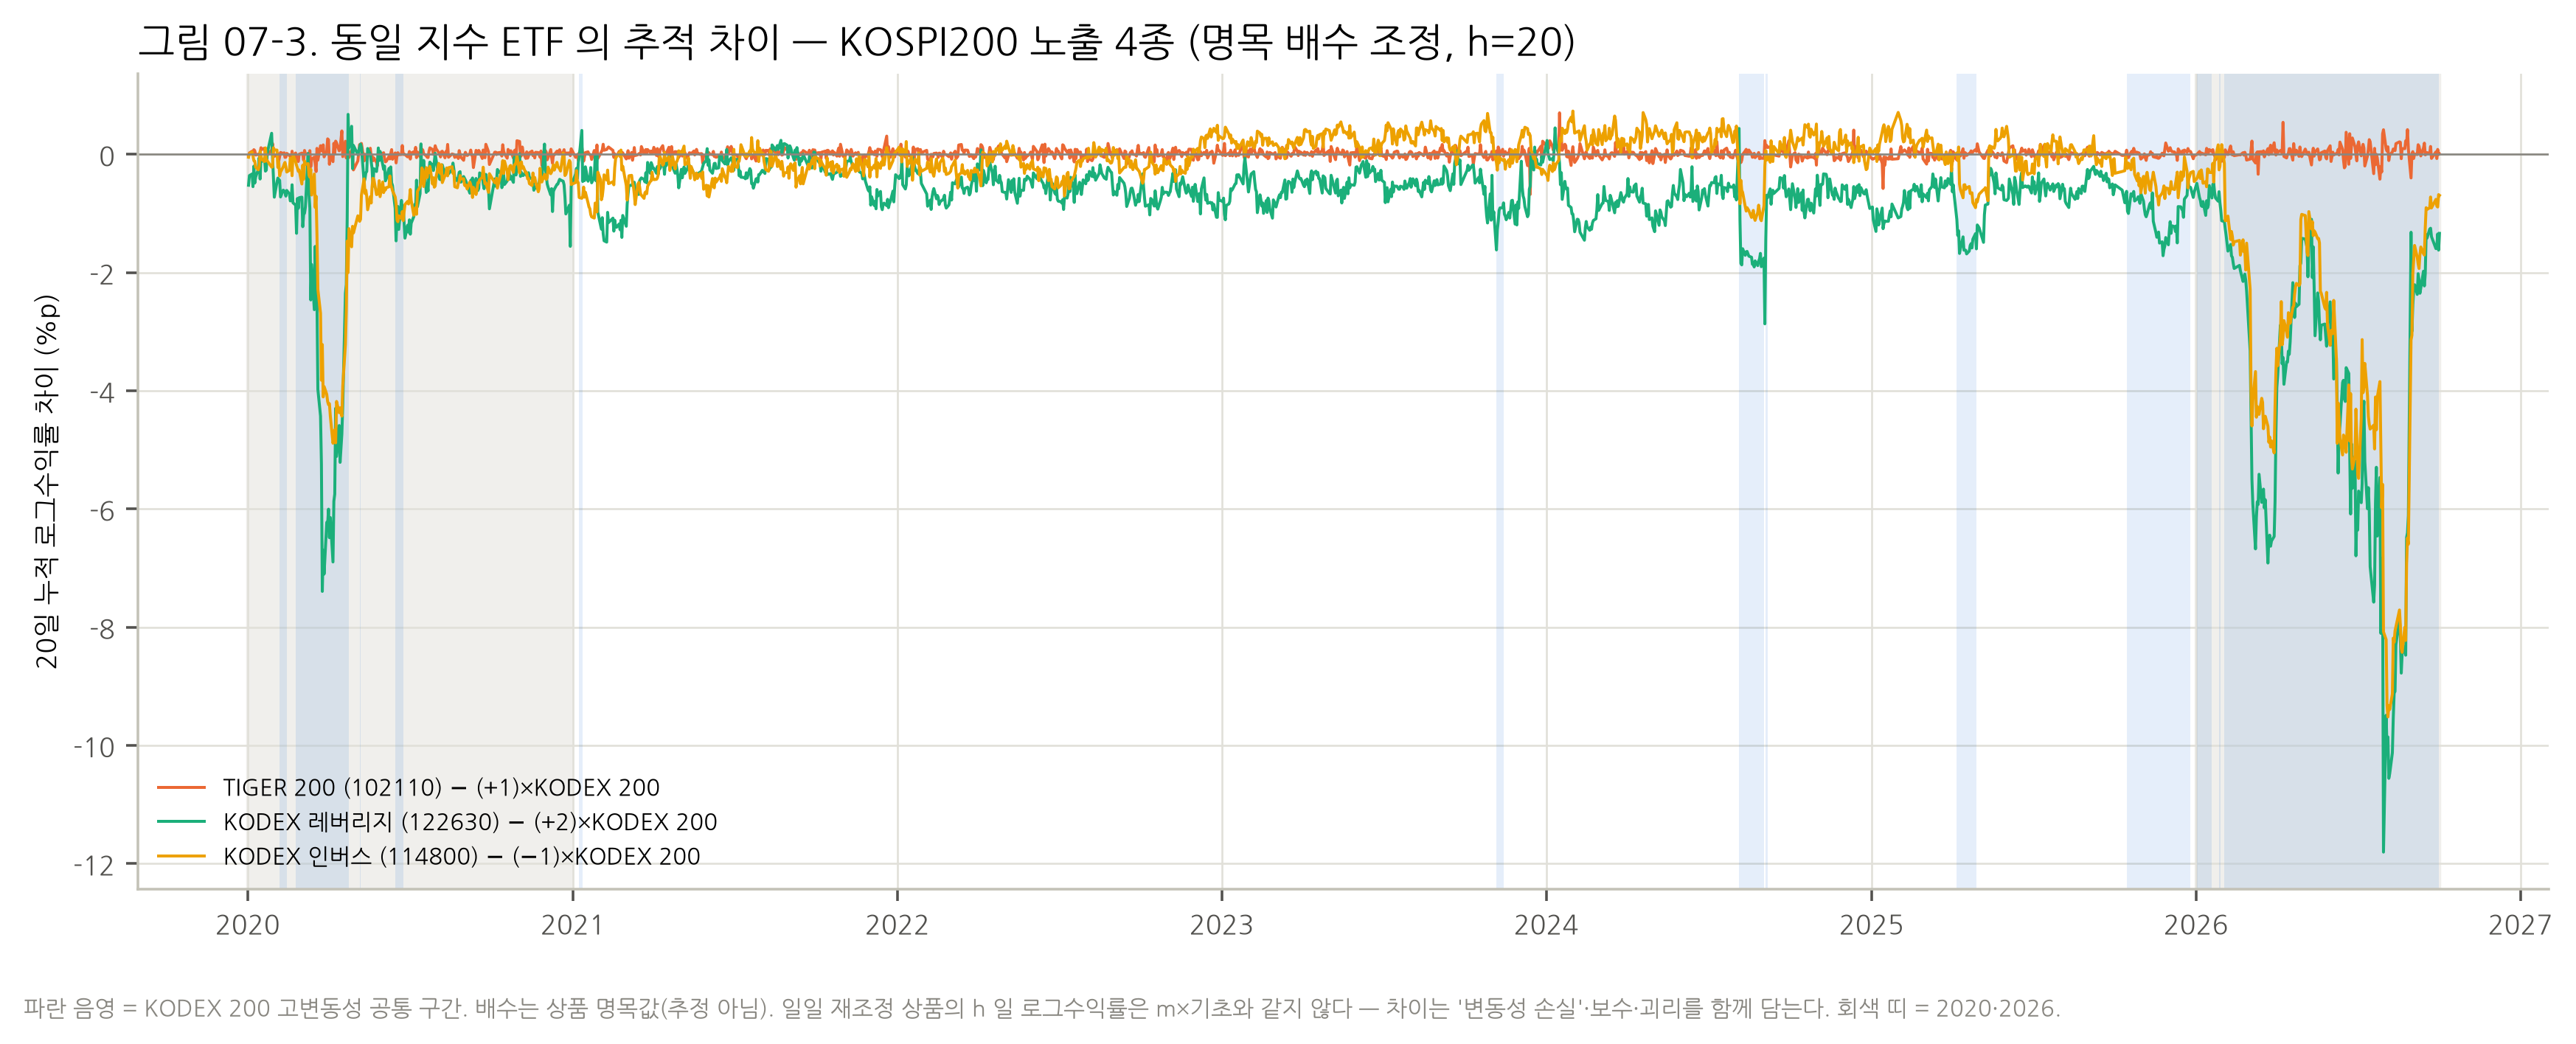

In [8]:
# KOSPI200 그룹: 명목 배수 조정 후 069500 대비 20일 차이 (C_i − m_i·C_069500), 069500 고변동성 후보일 여부로 나눔.
TR = same_exposure_tracking(REL, OV, CFG)  # 추적 차이 요약 (2021–2025)
display(TR.round(3))  # 069500 행은 102110 − 069500 (같은 값이 두 행에 나온다)
IV = S07["intervals"]  # 05·06 구간표
FIG_FILES += F.tracking_figure(REL, IV[(IV.ticker == "069500") & (IV.channel == "HIGH_LEVEL")], S07["expo"].set_index("ticker").name.to_dict(), FIG, "07-3")  # 그림 07-3
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시

**해석 (그림 07-3).**
- **같은 배수 상품 (TIGER 200 대 KODEX 200).** 20일 차이 중앙값은 +0.01%p, 10–90% 범위는 ±0.1%p 안쪽이다. 고변동성 여부와 거의 무관하다.
- **레버리지 122630.** '2×KODEX 200' 대비 20일 차이 중앙값이 평소 −0.54%p 다. KODEX 200 고변동성 후보일에는 **−1.21%p** 로 두 배 넘게 벌어진다.
- **인버스 114800.** 같은 비교에서 +0.03 → **−0.53%p** 다.
- 일일 재조정 상품은 기초지수 분산이 클수록 h 일 로그수익률이 m×기초보다 작아진다 (변동성 손실, 대략 $-\tfrac{m(m-1)}{2}\sigma^2 h$). 관찰된 방향과 크기 순서(레버리지 > 인버스 > 1배)는 이 설명과 맞는다. 다만 보수·괴리·배당 차이를 분리해 검정하지는 않았다.
- **시사점.** 변동성 국면에서는 '같은 노출' 상품끼리도 가격 반응이 체계적으로 달라진다. 레버리지·인버스의 가격 급등·급락을 기초지수 급등·급락과 같은 사건으로 라벨링하면 오차가 생긴다.

## 8. CUSUM 경보와 가격 움직임의 시간적 관계

,w,group,n,n_etf,median_C20,share_C20_neg,median_absZ20_A,median_fwd_R20,n_fwd
0,20,first_alarm,2,2,9.366,0.000,1.323,-2.798,2
1,20,no_alarm,12588,20,0.325,0.430,0.693,0.293,12588
2,30,alarm_other,17,3,1.618,0.176,0.731,-3.363,17
3,30,first_alarm,11,6,1.147,0.091,0.836,0.353,11
4,30,no_alarm,12562,20,0.324,0.430,0.693,0.294,12562
5,60,alarm_other,85,9,0.537,0.400,0.657,-2.481,85
6,60,first_alarm,18,11,0.345,0.500,1.052,1.946,18
7,60,no_alarm,12487,20,0.324,0.430,0.694,0.297,12487
8,120,alarm_other,137,6,1.277,0.204,0.978,0.692,137
9,120,first_alarm,12,7,0.486,0.250,1.063,0.159,12


경보가 겹친 2021–25 구간: 33 개 · 시차 중앙값 1.0 일 · 같은 날 16 개 · 최대 25 일


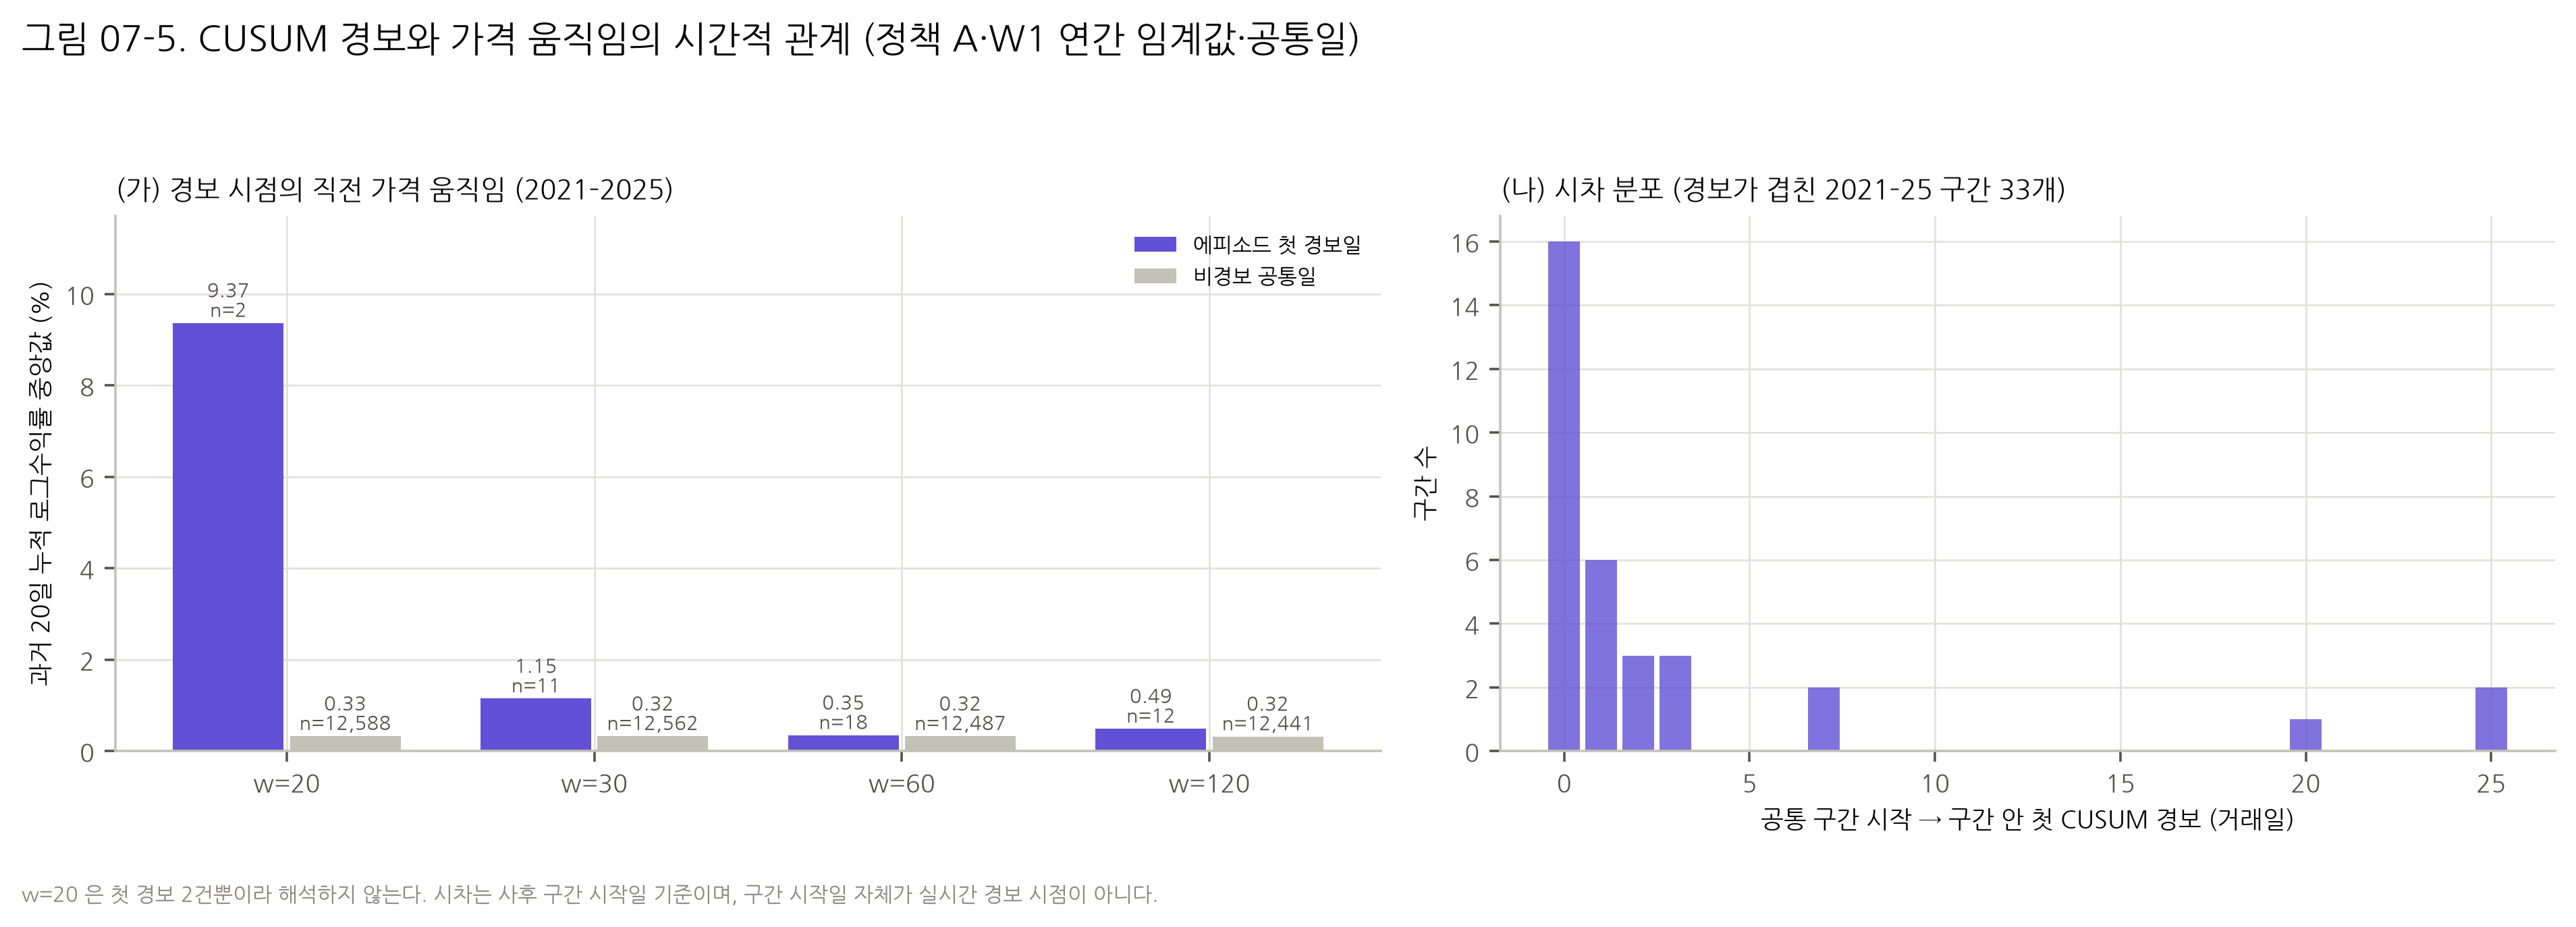

In [9]:
# CUSUM 첫 경보일 대 비경보 공통일의 과거 20일 수익률, 그리고 공통 구간 시작 → 구간 안 첫 경보 시차.
CPS = pd.read_csv(BASE / "results/07/cusum_alarm_price_summary.csv")  # 요약 (2021–2025)
display(CPS.round(3))  # w × 그룹
IDX = RW.index  # 거래일 축
q = IV[(IV.year_status == "PRIMARY") & IV.cusum_first_alarm_in_interval.notna()]  # 경보가 겹친 2021–25 구간
LAGS = pd.Series([IDX.get_loc(pd.Timestamp(a)) - IDX.get_loc(pd.Timestamp(s)) for s, a in zip(q.interval_start, q.cusum_first_alarm_in_interval, strict=True)])  # 시차 (거래일)
print("경보가 겹친 2021–25 구간:", len(LAGS), "개 · 시차 중앙값", LAGS.median(), "일 · 같은 날", int((LAGS == 0).sum()), "개 · 최대", LAGS.max(), "일")  # 요약
FIG_FILES += F.cusum_price_figure(CPS, LAGS, FIG, "07-5")  # 그림 07-5
display(Image(filename=str(FIG_FILES[-2]), width=950))  # 표시

**해석 (그림 07-5).**
- **경보 직전 가격.** CUSUM 첫 경보일의 과거 20일 수익률 중앙값은 비경보 공통일(+0.32%)보다 대체로 높다. w=30 은 +1.15%, w=120 은 +0.49% 다. w=60 은 +0.35% 로 비슷하다.
  - 첫 경보는 11–18건뿐이다. 그래서 방향을 일반화하지 않는다.
  - 특히 w=20 (2건)은 해석하지 않는다.
- **시차.** 2021–2025 공통 구간 가운데 CUSUM 경보가 겹친 33개 구간에서, 첫 경보는 구간 시작과 같은 날이 16개다. 중앙값은 1거래일 뒤이고, 최대 25일이다.
  - 같은 날 일어난 경우가 많은 것은 두 신호가 같은 큰 수익률 하나에 함께 반응하기 때문으로 보인다. 독립적인 '조기 경보' 가 아니다.
  - 연초 119 거래일은 CUSUM 을 계산할 수 없어, 그 시기의 구간은 비교에서 빠진다 (05 §13: 496/1,168 구간).

## 9. CNN 특징학습 후보 구간 계약

In [10]:
# CNN 후보 표: 사용자 §10 필수 22개 정보가 모두 복원되는지, 정답 라벨 열이 없는지 확인한다.
CNN = S07["cnn"]  # 후보 구간 표
REQUIRED = {"candidate_id": "candidate_id", "ticker": "ticker", "exposure_group": "exposure_group", "episode_state": "episode_state", "episode_start": "episode_start", "episode_end": "episode_end", "available_at": "available_at", "episode_confirmed_at": "episode_confirmed_at", "estimated_change_at": "estimated_change_at", "active_q": "active_q", "max_overlap_count": "max_overlap_count", "duration_trading_days": "duration_trading_days", "realized_variance_features": "rv_*", "relative_variance_features": "rel_*", "price_response_features": "px_*", "cusum_w": "cusum_w", "cusum_statistic": "cusum_statistic", "cusum_alarm_at": "cusum_alarm_at", "cusum_threshold_type": "cusum_threshold_type", "is_exploratory_candidate": "is_exploratory_candidate", "source_commit": "source_commit", "protocol_version": "protocol_version"}  # 필수 필드 → 실제 열
for need, col in REQUIRED.items():  # 22개 확인
    ok = any(c.startswith(col[:-1]) for c in CNN.columns) if col.endswith("*") else col in CNN.columns  # 접두사 또는 정확한 열
    assert ok, f"CNN 필수 필드 누락: {need}"  # 누락이면 중단
assert len(REQUIRED) == 22 and not any("label" in c.lower() for c in CNN.columns)  # 22개 · 라벨 열 없음
assert CNN.is_exploratory_candidate.all() and (CNN.estimated_change_at == "NOT_ESTIMATED").all()  # 탐색 후보 · 변화점 미추정
assert CNN.candidate_id.is_unique  # 후보 ID 유일
print("CNN 후보:", len(CNN), "행 ·", CNN.shape[1], "열 · 2021–25", int((CNN.year_status == "PRIMARY").sum()), "행 · 사후 20일 자료 끝 결측", int((CNN.px_post_available_at_h20 == "NOT_AVAILABLE_DATA_END").sum()), "행")  # 요약
display(CNN.groupby(["episode_state", "year_status"]).size().unstack(fill_value=0))  # 채널 × 연도 지위
display(CNN.head(3).T)  # 열 예시

CNN 후보: 1711 행 · 41 열 · 2021–25 1168 행 · 사후 20일 자료 끝 결측 47 행


year_status,PARTIAL_NON_BLIND,PILOT,PRIMARY
episode_state,,,
CONTRACTION,73,97,262
EXPANSION,119,60,253
HIGH_LEVEL,59,82,290
LOW_LEVEL,24,29,363


,0,1,2
candidate_id,W2-133690-CON-20250702,W2-261220-CON-20200715,W2-122630-CON-20200728
ticker,133690,261220,122630
exposure_group,133690,261220,KOSPI200_동일노출
episode_state,CONTRACTION,CONTRACTION,CONTRACTION
episode_start,2025-07-02,2020-07-15,2020-07-28
episode_end,2025-07-24,2020-07-28,2020-08-10
available_at,2025-07-02 close,2020-07-15 close,2020-07-28 close
episode_confirmed_at,2025-07-25,2020-07-29,2020-08-11
estimated_change_at,NOT_ESTIMATED,NOT_ESTIMATED,NOT_ESTIMATED
active_q,"3,14,20,30,60","3,14,20,30,60","3,14,20,30,60"


**CNN 인계 계약 (요약).** 전체 필드 사전은 `research/multihorizon_w2/CNN_후보구간_인계계약_W2.md` 에 있다.

- **후보는 정답이 아니다.**
  - `cnn_candidate_intervals_w2.csv` 는 분산 분위 규칙으로 만든 **탐색 후보**다. 행은 ETF·채널별 공통 구간 1,711개다.
  - '가격 급등' 이나 '구조변화' 의 정답 라벨로 쓰지 않는다. 표에 라벨 열을 만들지 않았다.
- **시점.**
  - `available_at` 은 구간 첫날 종가 이후다. 3개 이상 q 가 동시에 켜진 것을 그날 종가 후 안다.
  - `episode_confirmed_at` 은 구간이 끝났음을 아는 날이다.
  - `px_post_*` 열은 구간 종료 뒤 h 일의 **사후 결과**다. 입력 특징으로 쓰면 미래 정보 누수다.
- **중복.**
  - KOSPI200 4종의 구간은 거의 같은 날짜다 (06: Jaccard 0.75–0.99).
  - 학습·평가를 분할할 때는 `exposure_group` 단위로 묶어야 같은 사건이 두 쪽에 들어가지 않는다.
- **W1 후보와의 관계.** W1 의 `cnn_candidate_intervals.csv` (CUSUM 첫 경보, 142행)와는 다른 규칙이다. 두 표를 합쳐 중복 학습하지 않는다.
- **CNN 을 급등 탐지기로 평가하려면 먼저 필요한 것들** (W1 인계 계약과 같음):
  1. 독립 가격 급등 라벨과 허용 시차
  2. 음성 사례 정의
  3. 온라인 정보 차단
  4. 자산·기간 블라인드 분리
  5. 사전 비용 지표

## 10. 전체 W2 연구의 통합 해석

In [11]:
# 주장–근거 대조: 07 본문 수치를 결과에서 다시 계산해 확인한다.
CLAIMS = {  # 본문 수치
    # 본문 주장 (계산값, 본문값)
    "기준선 20일 fwd_R 중앙값": (round(UNCOND[20], 2), 0.38),
    # 본문 주장 (계산값, 본문값)
    "구간 중 상승 비율 HIGH/EXP/LOW/CON": (tuple(summ.during_양수비율.reindex(["HIGH_LEVEL", "EXPANSION", "LOW_LEVEL", "CONTRACTION"]).round(3)), (0.603, 0.565, 0.512, 0.531)),
    # 본문 주장 (계산값, 본문값)
    "구간 중 중앙값 HIGH": (round(float(summ.loc["HIGH_LEVEL", "during_C"]), 2), 0.51),
    # 본문 주장 (계산값, 본문값)
    "사후 20일 중앙값 HIGH/CON/EXP/LOW": (tuple(summ.post_R_h20.reindex(["HIGH_LEVEL", "CONTRACTION", "EXPANSION", "LOW_LEVEL"]).round(2)), (0.69, 0.57, 0.25, -0.19)),
    # 본문 주장 (계산값, 본문값)
    "사전 20일 중앙값 LOW/CON/EXP/HIGH": (tuple(summ.pre_C_h20.reindex(["LOW_LEVEL", "CONTRACTION", "EXPANSION", "HIGH_LEVEL"]).round(2)), (1.11, 1.4, 0.11, 0.16)),
    # 본문 주장 (계산값, 본문값)
    "2026 사후 20일 자료 끝 결측 CON/HIGH": ((int(NA_END.loc["PARTIAL_NON_BLIND", "CONTRACTION"]), int(NA_END.loc["PARTIAL_NON_BLIND", "HIGH_LEVEL"])), (30, 14)),
    # 본문 주장 (계산값, 본문값)
    "2021–25 자료 끝 결측": (int(NA_END.loc["PRIMARY"].sum()), 0),
    # 본문 주장 (계산값, 본문값)
    "확대 후보일 U_C 중앙값 (후보, 비후보)": (tuple(RT[RT.channel == "EXPANSION"].set_index("overlap_candidate_day").median_U_C.reindex([True, False]).round(2)), (0.42, 0.5)),
    # 본문 주장 (계산값, 본문값)
    "확대 후보일 단순 상대 중앙값": (round(float(RT[(RT.channel == "EXPANSION") & RT.overlap_candidate_day].median_rel_simple.iloc[0]), 2), 0.28),
    # 본문 주장 (계산값, 본문값)
    "고변동성 후보일 노출 조정 상대": (round(float(RT[(RT.channel == "HIGH_LEVEL") & RT.overlap_candidate_day].median_rel_exposure_adj.iloc[0]), 2), 0.21),
    # 본문 주장 (계산값, 본문값)
    "축소 후보일 단순·노출조정 상대": (tuple(RT[(RT.channel == "CONTRACTION") & RT.overlap_candidate_day][["median_rel_simple", "median_rel_exposure_adj"]].iloc[0].round(2)), (-0.17, -0.26)),
    # 본문 주장 (계산값, 본문값)
    "저변동성 후보일 다른 자산유형 대비": (round(float(RT[(RT.channel == "LOW_LEVEL") & RT.overlap_candidate_day].median_rel_cross_asset.iloc[0]), 2), 0.23),
    # 본문 주장 (계산값, 본문값)
    "레버리지 추적 차이 (비후보, 후보)": (tuple(TR[TR.ticker == "122630"].set_index("overlap_candidate_day")["median"].reindex([False, True]).round(2)), (-0.54, -1.21)),
    # 본문 주장 (계산값, 본문값)
    "인버스 추적 차이 (비후보, 후보)": (tuple(TR[TR.ticker == "114800"].set_index("overlap_candidate_day")["median"].reindex([False, True]).round(2)), (0.03, -0.53)),
    # 본문 주장 (계산값, 본문값)
    "CUSUM 겹침 구간 시차 (n, 같은 날, 중앙값, 최대)": ((len(LAGS), int((LAGS == 0).sum()), float(LAGS.median()), int(LAGS.max())), (33, 16, 1.0, 25)),
    # 본문 주장 (계산값, 본문값)
    "CUSUM 첫 경보 과거 20일 중앙값 w30/w60/w120": (tuple(CPS[CPS.group == "first_alarm"].set_index("w").median_C20.reindex([30, 60, 120]).round(2)), (1.15, 0.35, 0.49)),
    # 본문 주장 (계산값, 본문값)
    "평균 경로 −60일 (HIGH, EXP, LOW, CON)": (tuple(round(float(PM.loc[c][("path", "mean")].loc[-60]), 2) for c in ("HIGH_LEVEL", "EXPANSION", "LOW_LEVEL", "CONTRACTION")), (-1.87, -3.28, -2.14, -2.07)),
    # 본문 주장 (계산값, 본문값)
    "평균 경로 +60일 (HIGH, EXP, CON, LOW)": (tuple(round(float(PM.loc[c][("path", "mean")].loc[60]), 2) for c in ("HIGH_LEVEL", "EXPANSION", "CONTRACTION", "LOW_LEVEL")), (3.84, 3.24, 2.65, 0.56)),
    # 본문 주장 (계산값, 본문값)
    "확대 상대 경로 −60일 평균, 중앙 경로 −60·+60": ((round(float(PM.loc["EXPANSION"][("path_rel", "mean")].loc[-60]), 2), round(float(PM.loc["EXPANSION"][("path", "median")].loc[-60]), 2), round(float(PM.loc["EXPANSION"][("path", "median")].loc[60]), 2)), (-2.23, -0.45, 1.54)),
    # 본문 주장 (계산값, 본문값)
    "CNN 후보 행 수": (len(CNN), 1711),
    # 본문 주장 (계산값, 본문값)
    "사후 20일 상대 (4채널 모두 음수)": (bool((summ.post_rel_h20 < 0).all()), True),
}  # 끝
for k, (got, want) in CLAIMS.items():  # 하나씩
    assert got == want, f"{k}: 계산 {got} ≠ 본문 {want}"  # 불일치면 중단
    print(f"✓ {k}: {got}")  # 확인

✓ 기준선 20일 fwd_R 중앙값: 0.38
✓ 구간 중 상승 비율 HIGH/EXP/LOW/CON: (0.603, 0.565, 0.512, 0.531)
✓ 구간 중 중앙값 HIGH: 0.51
✓ 사후 20일 중앙값 HIGH/CON/EXP/LOW: (0.69, 0.57, 0.25, -0.19)
✓ 사전 20일 중앙값 LOW/CON/EXP/HIGH: (1.11, 1.4, 0.11, 0.16)
✓ 2026 사후 20일 자료 끝 결측 CON/HIGH: (30, 14)
✓ 2021–25 자료 끝 결측: 0
✓ 확대 후보일 U_C 중앙값 (후보, 비후보): (0.42, 0.5)
✓ 확대 후보일 단순 상대 중앙값: 0.28
✓ 고변동성 후보일 노출 조정 상대: 0.21
✓ 축소 후보일 단순·노출조정 상대: (-0.17, -0.26)
✓ 저변동성 후보일 다른 자산유형 대비: 0.23
✓ 레버리지 추적 차이 (비후보, 후보): (-0.54, -1.21)
✓ 인버스 추적 차이 (비후보, 후보): (0.03, -0.53)
✓ CUSUM 겹침 구간 시차 (n, 같은 날, 중앙값, 최대): (33, 16, 1.0, 25)
✓ CUSUM 첫 경보 과거 20일 중앙값 w30/w60/w120: (1.15, 0.35, 0.49)
✓ 평균 경로 −60일 (HIGH, EXP, LOW, CON): (-1.87, -3.28, -2.14, -2.07)
✓ 평균 경로 +60일 (HIGH, EXP, CON, LOW): (3.84, 3.24, 2.65, 0.56)
✓ 확대 상대 경로 −60일 평균, 중앙 경로 −60·+60: (-2.23, -0.45, 1.54)
✓ CNN 후보 행 수: 1711
✓ 사후 20일 상대 (4채널 모두 음수): True


### H5 판정

| 지지하는 관찰 | 지지하지 않는·제한하는 관찰 |
|---|---|
| 국면별 사전 가격이 다르다: 저변동성·축소는 조용한 상승(+1.1–1.4%) 뒤, 확대는 약한 가격(+0.11%, U_C 0.42) 뒤에 나타난다. 확대 후보일은 같은 날 다른 ETF 보다 덜 빠졌다 (+0.28%p). 레버리지·인버스의 추적 차이는 고변동성일에 두 배 이상 벌어진다 | 구간 중 상승 비율이 51–60% 로, 변동성 국면이 가격 방향을 정하지 않는다. 사후 20일 '나머지 19종 대비' 값은 네 채널 **모두** 음수다 (−0.18~−0.67%p). 채널과 무관한 공통 편향이므로 국면 효과가 아니라 구성 효과(구간이 많은 채권·단기채권 등 저수익 종목)일 가능성이 크다. 겹친 구간들이라 독립 표본이 아니다 |

### 통합 해석 — W2 전체 (05·06·07)

1. **수준과 변화는 다른 것을 본다 (H1).**
   - 고변동성 수준은 길게 지속되고, 확대는 그 상태로 들어가는 짧은 시기에 몰린다.
   - 두 후보일의 Jaccard 중앙값은 0.27 이다.
2. **여러 시간 규모의 동시 반응은 흔하지만 '유의함' 은 아니다 (H2).**
   - 2021–2025 공통 구간은 1,168개이고, 그 가운데 7/7 은 고변동성 23 · 확대 2 다.
   - 보정된 귀무분포가 없다.
3. **W1 CUSUM 은 RV 수준과 거의 무관하다 (H3).**
   - ρ 중앙값은 −0.11~−0.01 이다.
   - 공통 구간의 42% 는 연초 미계산 기간이라 CUSUM 과 비교할 수 없다.
   - W1 비적격 판정은 유지한다.
4. **공통성은 노출 구조로 상당 부분 설명된다 (H4).**
   - 같은 지수 4종은 사실상 한 신호다.
   - 서로 다른 노출이 함께 반응한 2021–2025 사건은 2024-08 · 2025-04 (확대, 10–11/17 그룹)와 2022 채권·통화 주도 고변동성이다.
5. **변동성 국면은 가격 방향 라벨이 아니다 (H5).**
   - 상승과 하락이 섞여 있다.
   - 같은 노출 상품끼리도 레버리지 구조에 따라 반응이 체계적으로 다르다.

**이 연구가 주장하지 않는 것.**
- CUSUM 이 참 구조변화 시점을 찾았다.
- 여러 기간이 겹쳤으므로 유의하다.
- q=1 은 안정적 레짐이다.
- 구간 시작일이 실시간 경보 시점이다.
- CNN 후보가 급등 정답이다.
- 이번 분석이 독립 외부 검증이다.

## 11. 재현성 — 결과 해시와 릴리스 인계

In [12]:
# 07 그림 색인과 05·06·07 전체 결과 해시를 묶은 인계 파일.
fig_index = pd.DataFrame({"file": [str(p.relative_to(BASE)) for p in FIG_FILES], "sha256": [sha256(p) for p in FIG_FILES]})  # 그림 해시
fig_index.to_csv(BASE / "results/07/figure_index_07.csv", index=False)  # 그림 색인
MAN7 = S07["manifest"]  # 07 결과 해시
final = {"from": "07", "protocol_version": CFG["protocol_version"], "config_sha256": FREEZE[0][0], "contract_sha256": FREEZE[1][0], "environment": ACTUAL_ENV, "results": {**H06["results"], **MAN7["files_sha256"]}, "work_files": {**H06["work_files"], **MAN7["work_sha256"]}, "figure_indexes": {k: sha256(BASE / f"results/{k}/figure_index_{k}.csv") for k in ("05", "06", "07")}}  # 최종 인계
(BASE / "results/07_final.json").write_text(json.dumps(final, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")  # 저장
print("결과 파일", len(final["results"]), "개 · Git 제외 작업 파일", len(final["work_files"]), "개 · 그림", len(FIG_FILES) // 2, "개")  # 요약

결과 파일 26 개 · Git 제외 작업 파일 7 개 · 그림 5 개
